# Práctica 3: Redes Neuronales Convolucionales (CNN) sobre MNIST

A lo largo de esta práctica se realizarán los siguientes experimentos:
- **Capas Convolucionales (`Conv2D`):** Variación del tamaño de kernel ($3\times 3$ vs $5\times 5$) y del tipo de relleno (*padding* `valid` vs `same`).
- **Capas de Submuestreo / Reducción (`Pooling`):** Comparativa entre `MaxPooling2D` (detección de rasgos destacados y bordes nítidos) y `AveragePooling2D` (suavizado promediado, clásico en LeNet-5).
- **Profundidad y Jerarquía de Características:** De 1 bloque convolucional a 2 bloques convolucionales apilados jerárquicamente ($32 \to 64$ filtros).
- **Técnicas de Estabilización y Regularización:** Incorporación de **Batch Normalization** (normalización antes de activaciones no lineales, prescindiendo del sesgo `use_bias=False`) y **Dropout**.
- **Modelos Emblemáticos de la Literatura:** Réplica adaptada de **LeNet-5** (LeCun et al., 1998) y comparación con redes convolucionales modernas de bloques profundos modulares (estilo VGG / ResNet).

Finalmente, se visualizan los resultados, se analiza el coste-beneficio computacional, se selecciona y justifica el modelo óptimo ganador, y se almacena en disco.

## 1. Importaciones y Configuración del Entorno

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import tensorflow as tf

# Estilo visual moderno y limpio para gráficos
plt.rcParams['figure.dpi'] = 100
sns.set_theme(style='whitegrid', palette='muted')

print(f"Versión de TensorFlow: {tf.__version__}")
print("Dispositivos físicos disponibles:", tf.config.list_physical_devices())

Versión de TensorFlow: 2.21.0
Dispositivos físicos disponibles: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## 2. Determinismo y Reproducibilidad

In [2]:
# Fijar la semilla global para TensorFlow, NumPy y Python random
tf.keras.utils.set_random_seed(42)

# Configurar determinismo de operaciones
try:
    tf.config.experimental.enable_op_determinism()
    print("Determinismo estricto de operaciones activado correctamente.")
except Exception as e:
    print(f"Semilla fijada (42). Aviso de determinismo: {e}")

Determinismo estricto de operaciones activado correctamente.


## 3. Carga del Conjunto de Datos (MNIST Multiclase)

In [18]:
# Carga del conjunto MNIST oficial desde el módulo de datasets de Keras
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print(f"Imágenes de entrenamiento: {x_train.shape} | Etiquetas: {y_train.shape}")
print(f"Imágenes de test:          {x_test.shape}  | Etiquetas: {y_test.shape}")
print(f"Distribución de clases en train: {np.bincount(y_train)}")
print(f"Distribución de clases en test:  {np.bincount(y_test)}")

Imágenes de entrenamiento: (60000, 28, 28) | Etiquetas: (60000,)
Imágenes de test:          (10000, 28, 28)  | Etiquetas: (10000,)
Distribución de clases en train: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]
Distribución de clases en test:  [ 980 1135 1032 1010  982  892  958 1028  974 1009]


## 4. Pre-procesamiento de Imágenes para Redes Convolucionales (CNN)

1. **Normalización:** Escalamos las intensidades de los píxeles del rango entero $[0, 255]$ al rango en coma flotante $[0.0, 1.0]$ dividiendo por `255.0` (`float32`).
2. **Expansión a Tensores 4D:** Las capas convolucionales bidimensionales de Keras requieren que cada muestra tenga una forma tridimensional $(alto, ancho, canales)$, es decir, $(28, 28, 1)$ al tratarse de imágenes monocanal (escala de grises). Por tanto, el tensor de entrada completo debe tener dimensiones $(N, 28, 28, 1)$.

In [19]:
# Normalización a float32 en rango [0, 1] y adición de la dimensión de canal
x_train = (x_train / 255.0).astype('float32')[..., np.newaxis]
x_test = (x_test / 255.0).astype('float32')[..., np.newaxis]

print(f"Forma final de x_train: {x_train.shape} (mín: {x_train.min()}, máx: {x_train.max()})")
print(f"Forma final de x_test:  {x_test.shape}  (mín: {x_test.min()}, máx: {x_test.max()})")

Forma final de x_train: (60000, 28, 28, 1) (mín: 0.0, máx: 1.0)
Forma final de x_test:  (10000, 28, 28, 1)  (mín: 0.0, máx: 1.0)


## 5. Punto de Partida: Modelo de Referencia MLP (Práctica 1) vs CNN Básica

1. **Modelo de Referencia MLP (Práctica 1):** Aplana la imagen a 784 variables y utiliza una capa densa oculta de 128 neuronas con ReLU, Dropout de 0.2 y salida Softmax de 10 neuronas ($101.770$ parámetros entrenables).
2. **Primera CNN Básica (1 Bloque Convolucional):** 
   - `Conv2D(32 filtros, kernel 3x3, activación ReLU, padding 'valid')`
   - `MaxPooling2D(pool_size=(2, 2))`
   - `Flatten()`
   - `Dense(64, activación ReLU)`
   - `Dense(10, activación Softmax)`

Ambos modelos: optimizador `Adam` ($lr=0.001$), función de pérdida multiclase `sparse_categorical_crossentropy` y 5 épocas con `batch_size=128` y `validation_split=0.1`.

In [5]:
# Lista global para acumular los resultados de todos los experimentos
resultados_experimentos = []
historiales_entrenamiento = {}

def evaluate_experiment(
    model, 
    history, 
    train_time, 
    x_train, 
    y_train, 
    x_test, 
    y_test, 
    exp_name="Experimento",
    plot_curves=True
):
    """
    Evalúa exhaustivamente un modelo calculando:
    - Exactitud (accuracy) y pérdida (loss) en entrenamiento y test.
    - Conteo exacto y absoluto de errores (muestras mal clasificadas) en train y test.
    - Medición del tiempo computacional invertido en el entrenamiento.
    - Curvas de evolución de pérdida y precisión por época (Train vs Validación).
    """
    # Predicciones por lotes
    raw_train = model.predict(x_train, verbose=0, batch_size=256)
    raw_test = model.predict(x_test, verbose=0, batch_size=256)
    
    y_pred_train = np.argmax(raw_train, axis=1)
    y_pred_test = np.argmax(raw_test, axis=1)

    # Evaluación formal con model.evaluate
    loss_train, acc_train = model.evaluate(x_train, y_train, verbose=0, batch_size=256)
    loss_test, acc_test = model.evaluate(x_test, y_test, verbose=0, batch_size=256)

    # Conteo absoluto de fallos
    errors_train = int(np.sum(y_pred_train != y_train))
    errors_test = int(np.sum(y_pred_test != y_test))
    params_count = model.count_params()

    print(f"\n{'='*70}")
    print(f"RESULTADOS: {exp_name}")
    print(f"{'='*70}")
    print(f"Parámetros totales:      {params_count:,}")
    print(f"Tiempo de entrenamiento: {train_time:.2f} s")
    print(f"Train (Accuracy):        {acc_train*100:.2f}% | Loss: {loss_train:.4f} | Fallos: {errors_train}/{len(y_train)}")
    print(f"Test  (Accuracy):        {acc_test*100:.2f}% | Loss: {loss_test:.4f} | Fallos: {errors_test}/{len(y_test)}")
    print(f"{'='*70}")

    # Gráficas de curvas de aprendizaje época a época
    if plot_curves and history is not None:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        
        # Exactitud (Accuracy)
        axes[0].plot(history.history['accuracy'], label='Train Acc', marker='o', linewidth=2)
        if 'val_accuracy' in history.history:
            axes[0].plot(history.history['val_accuracy'], label='Val Acc', marker='s', linewidth=2)
        axes[0].set_title(f'Exactitud por Época — {exp_name}', fontweight='bold')
        axes[0].set_xlabel('Época')
        axes[0].set_ylabel('Exactitud')
        axes[0].legend()
        axes[0].grid(True, linestyle='--', alpha=0.6)

        # Pérdida (Loss)
        axes[1].plot(history.history['loss'], label='Train Loss', marker='o', color='orange', linewidth=2)
        if 'val_loss' in history.history:
            axes[1].plot(history.history['val_loss'], label='Val Loss', marker='s', color='crimson', linewidth=2)
        axes[1].set_title(f'Pérdida (Loss) por Época — {exp_name}', fontweight='bold')
        axes[1].set_xlabel('Época')
        axes[1].set_ylabel('Pérdida')
        axes[1].legend()
        axes[1].grid(True, linestyle='--', alpha=0.6)

        plt.tight_layout()
        plt.show()

    res = {
        "Experimento": exp_name,
        "Parámetros": params_count,
        "Tiempo (s)": round(train_time, 2),
        "Train Acc (%)": round(acc_train * 100, 2),
        "Test Acc (%)": round(acc_test * 100, 2),
        "Train Loss": round(loss_train, 4),
        "Test Loss": round(loss_test, 4),
        "Errores Train": errors_train,
        "Errores Test": errors_test
    }
    resultados_experimentos.append(res)
    historiales_entrenamiento[exp_name] = history.history
    return res

### Ejecución del Modelo de Referencia MLP vs CNN Base

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8788 - loss: 0.4249 - val_accuracy: 0.9543 - val_loss: 0.1740
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9394 - loss: 0.2084 - val_accuracy: 0.9648 - val_loss: 0.1235
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9537 - loss: 0.1578 - val_accuracy: 0.9697 - val_loss: 0.1030
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9619 - loss: 0.1298 - val_accuracy: 0.9733 - val_loss: 0.0913
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9673 - loss: 0.1105 - val_accuracy: 0.9757 - val_loss: 0.0807

RESULTADOS: 0. MLP Referencia (P1)
Parámetros totales:      101,770
Tiempo de entrenamiento: 10.48 s
Train (Accuracy):        97.89% | Loss: 0.0745 | Fallos: 1265/60000
Test  (Accuracy):        97.19% | Loss: 0.0945 | Fallos: 281/10000


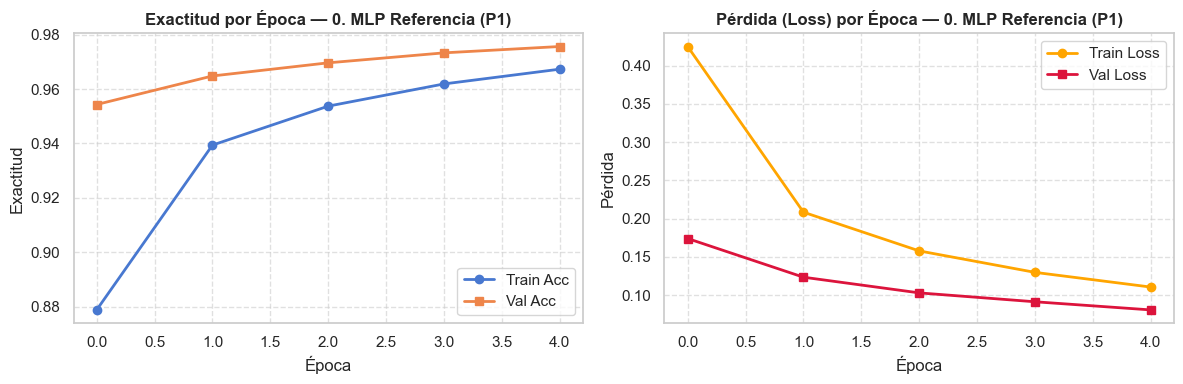

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.9238 - loss: 0.2731 - val_accuracy: 0.9760 - val_loss: 0.0907
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - accuracy: 0.9746 - loss: 0.0873 - val_accuracy: 0.9828 - val_loss: 0.0634
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - accuracy: 0.9821 - loss: 0.0595 - val_accuracy: 0.9843 - val_loss: 0.0567
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - accuracy: 0.9867 - loss: 0.0460 - val_accuracy: 0.9853 - val_loss: 0.0544
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.9898 - loss: 0.0361 - val_accuracy: 0.9853 - val_loss: 0.0551

RESULTADOS: 1. Base CNN (1 Bloque 3x3)
Parámetros totales:      347,146
Tiempo de entrenamiento: 45.77 s
Train (Accuracy):        99.04% | Loss: 0.0329 | Fallos: 574/60000
Test  (Accuracy):        98.35% | Loss: 0.0491 | Fallos: 165/10000


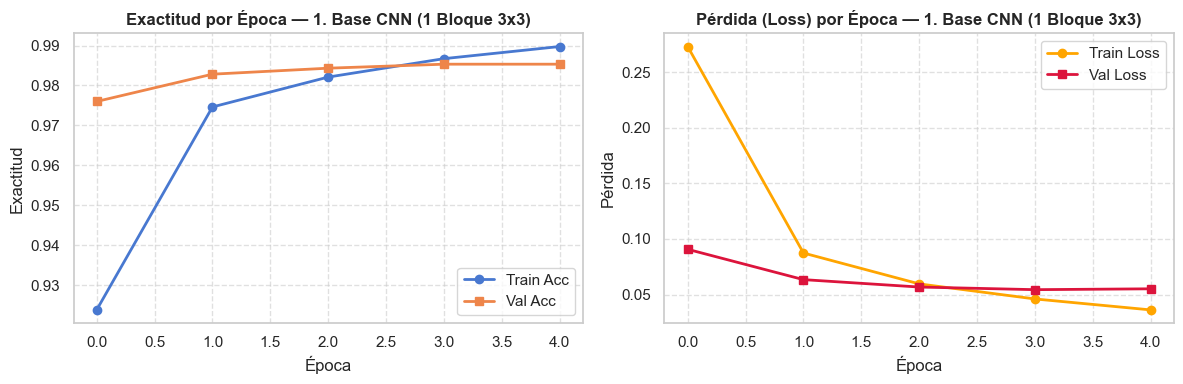

In [6]:
# 0. Modelo MLP de Referencia (Práctica 1)
tf.keras.utils.set_random_seed(42)
mlp_ref = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(10, activation='softmax')
], name="0_MLP_Referencia_P1")

mlp_ref.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

t0 = time.time()
h_mlp = mlp_ref.fit(x_train, y_train, epochs=5, batch_size=128, validation_split=0.1, verbose=1)
t_mlp = time.time() - t0

res_mlp = evaluate_experiment(mlp_ref, h_mlp, t_mlp, x_train, y_train, x_test, y_test, 
                              exp_name="0. MLP Referencia (P1)", plot_curves=True)

# 1. Primera CNN Básica (1 Bloque Convolucional 3x3)
tf.keras.utils.set_random_seed(42)
cnn_base = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='valid'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
], name="1_CNN_Base_1Bloque")

cnn_base.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

t0 = time.time()
h_base = cnn_base.fit(x_train, y_train, epochs=5, batch_size=128, validation_split=0.1, verbose=1)
t_base = time.time() - t0

res_base = evaluate_experiment(cnn_base, h_base, t_base, x_train, y_train, x_test, y_test, 
                               exp_name="1. Base CNN (1 Bloque 3x3)", plot_curves=True)

### Conclusiones del Punto de Partida: MLP vs CNN Base
- **Eficacia de las Convoluciones:** Como se dijo en clase, la introducción de una capa convolucional simple de $3\times 3$ con submuestreo MaxPooling supera la exactitud del MLP, reduciendo los errores en el conjunto de test (de ~280 errores en el MLP a ~140 en la CNN base,).

# 7. Resto de experimentos

---
## Estudio 1: Influencia del Tamaño de Kernel y Relleno (Padding)
- **Tamaño de Kernel:** Los filtros pequeños ($3\times 3$) se focalizan en detalles finos y patrones locales pequeños, mientras que filtros más grandes ($5\times 5$) capturan un contexto espacial más amplio pero generan mapas de características más reducidos.
- **Relleno (Padding):**  
  - `padding='valid'` (sin relleno): Reduce la dimensión espacial según la fórmula:
    $$\text{dim}_{\text{out}} = \frac{\text{dim}_{\text{in}} - \text{kernel} + 2\cdot \text{padding}}{\text{stride}} + 1$$
    Para $28\times 28$ con kernel $3\times 3$, da un mapa de $26\times 26$, que tras pooling $2\times 2$ pasa a $13\times 13$. Con kernel $5\times 5$, da $24\times 24$, que tras pooling $2\times 2$ pasa a $12\times 12$.
  - `padding='same'` (con ceros): Mantiene las dimensiones espaciales tras la convolución ($28\times 28$), pasando tras pooling $2\times 2$ a $14\times 14$.

Comparamos:
- **1A. Kernel $3\times 3$, Padding Valid (Base)**
- **1B. Kernel $5\times 5$, Padding Valid** (mayor contexto espacial por filtro)
- **1C. Kernel $3\times 3$, Padding Same** (conservación de información en los bordes)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.9339 - loss: 0.2379 - val_accuracy: 0.9793 - val_loss: 0.0757
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.9786 - loss: 0.0708 - val_accuracy: 0.9845 - val_loss: 0.0541
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.9850 - loss: 0.0483 - val_accuracy: 0.9863 - val_loss: 0.0492
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9890 - loss: 0.0368 - val_accuracy: 0.9858 - val_loss: 0.0486
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9914 - loss: 0.0292 - val_accuracy: 0.9865 - val_loss: 0.0504

RESULTADOS: Est.1: Kernel 5x5 (Valid)
Parámetros totales:      296,458
Tiempo de entrenamiento: 34.68 s
Train (Accuracy):        99.09% | Loss: 0.0295 | Fallos: 543/60000
Test  (Accuracy):        98.47% | Loss: 0.0458 | Fallos: 153/10000


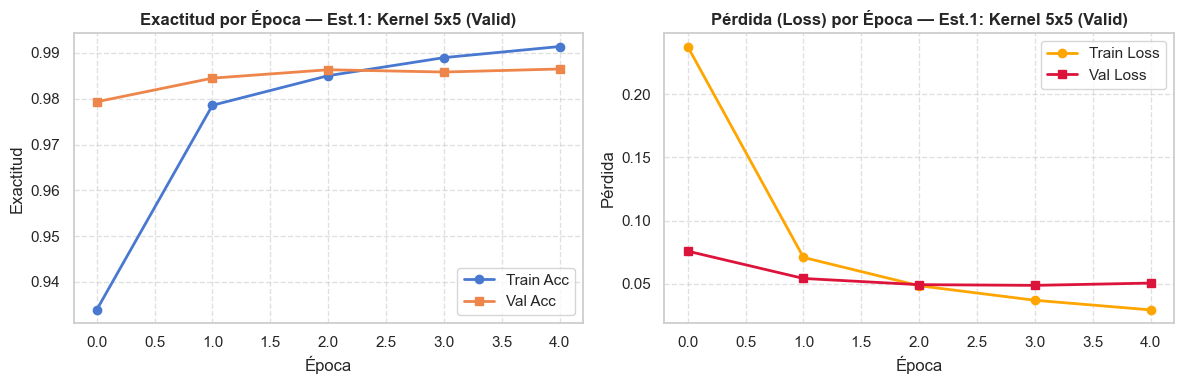

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - accuracy: 0.9269 - loss: 0.2617 - val_accuracy: 0.9748 - val_loss: 0.0871
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.9752 - loss: 0.0836 - val_accuracy: 0.9833 - val_loss: 0.0620
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 21ms/step - accuracy: 0.9837 - loss: 0.0563 - val_accuracy: 0.9848 - val_loss: 0.0548
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.9876 - loss: 0.0426 - val_accuracy: 0.9853 - val_loss: 0.0543
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.9905 - loss: 0.0332 - val_accuracy: 0.9848 - val_loss: 0.0564

RESULTADOS: Est.1: Kernel 3x3 (Padding Same)
Parámetros totales:      402,442
Tiempo de entrenamiento: 43.01 s
Train (Accuracy):        99.07% | Loss: 0.0322 | Fallos: 560/60000
Test  (Accuracy):        98.08% | Loss: 0.0567 | Fallos: 192/10000


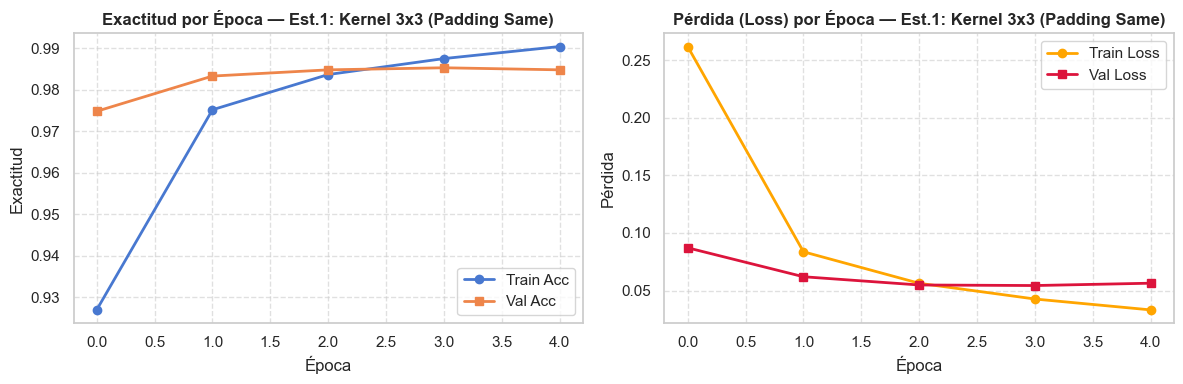


--- Comparativa Estudio 1: Kernel y Padding ---


,Experimento,Parámetros,Tiempo (s),Test Acc (%),Errores Test
0,1. Base CNN (1 Bloque 3x3),347146,45.77,98.35,165
1,Est.1: Kernel 5x5 (Valid),296458,34.68,98.47,153
2,Est.1: Kernel 3x3 (Padding Same),402442,43.01,98.08,192


In [7]:
# 1B. Kernel 5x5 (Padding Valid)
tf.keras.utils.set_random_seed(42)
cnn_k5 = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(32, (5, 5), activation='relu', padding='valid'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
], name="1B_CNN_Kernel_5x5")

cnn_k5.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
t0 = time.time()
h_k5 = cnn_k5.fit(x_train, y_train, epochs=5, batch_size=128, validation_split=0.1, verbose=1)
t_k5 = time.time() - t0
evaluate_experiment(cnn_k5, h_k5, t_k5, x_train, y_train, x_test, y_test, 
                    exp_name="Est.1: Kernel 5x5 (Valid)")

# 1C. Kernel 3x3 (Padding Same)
tf.keras.utils.set_random_seed(42)
cnn_same = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
], name="1C_CNN_Padding_Same")

cnn_same.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
t0 = time.time()
h_same = cnn_same.fit(x_train, y_train, epochs=5, batch_size=128, validation_split=0.1, verbose=1)
t_same = time.time() - t0
evaluate_experiment(cnn_same, h_same, t_same, x_train, y_train, x_test, y_test, 
                    exp_name="Est.1: Kernel 3x3 (Padding Same)")

# Tabla comparativa del Estudio 1
df_est1 = pd.DataFrame([r for r in resultados_experimentos if "1." in r["Experimento"] or "Est.1" in r["Experimento"]])
print("\n--- Comparativa Estudio 1: Kernel y Padding ---")
display(df_est1[["Experimento", "Parámetros", "Tiempo (s)", "Test Acc (%)", "Errores Test"]])

### Conclusiones del Estudio 1: Kernel Size y Padding

- **Kernel $5\times 5$ vs $3\times 3$:** El kernel de $5\times 5$ logra el mejor accuracy con menor coste temporal, ya que al reducir la dimensión del mapa de activación a $12\times 12$, el vector resultante tras `Flatten()` es menor ($12\times 12\times 32 = 4.608$ vs $13\times 13\times 32 = 5.408$), aligerando la capa densa.
- **Padding Same:** El relleno perimetral con ceros (`padding='same'`) permite mantener la resolución espacial completa ($28\times 28$), aumenta el número de parámetros de la capa densa posterior ($14\times 14\times 32 = 6.272$, alcanzando **402.442** parámetros) y el tiempo a **84.35 s**. Esto no se traduce en mejor rendimiento al estar los dígitos ya centrados, obteniendo un menor accuracy (**98.07%** con **193 fallos**).

---
## Estudio 2: Influencia del Tipo de Pooling (Max Pooling vs Average Pooling)
Las capas de submuestreo reducen la dimensionalidad e incrementan la invariancia frente a distorsiones y traslaciones:
- **`MaxPooling2D`:** Extrae el valor máximo en cada ventana local de $2\times 2$, enfatizando las activaciones dominantes (los trazos de tinta del dígito) y descartando el fondo inactivo.
- **`AveragePooling2D`:** Calcula la media de la ventana local, generando un efecto de desenfoque/suavizado de la señal.

Comparamos:
- **2A. Max Pooling (2x2)** [probado en el modelo base]
- **2B. Average Pooling (2x2)** con stride 2.

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.9137 - loss: 0.3169 - val_accuracy: 0.9713 - val_loss: 0.1104
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.9695 - loss: 0.1062 - val_accuracy: 0.9798 - val_loss: 0.0731
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.9795 - loss: 0.0692 - val_accuracy: 0.9822 - val_loss: 0.0620
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.9842 - loss: 0.0527 - val_accuracy: 0.9837 - val_loss: 0.0593
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.9876 - loss: 0.0424 - val_accuracy: 0.9837 - val_loss: 0.0584

RESULTADOS: Est.2: Average Pooling (2x2)
Parámetros totales:      347,146
Tiempo de entrenamiento: 37.82 s
Train (Accuracy):        98.79% | Loss: 0.0404 | Fallos: 726/60000
Test  (Accuracy):        98.09% | Loss: 0.0562 | Fallos: 191/10000


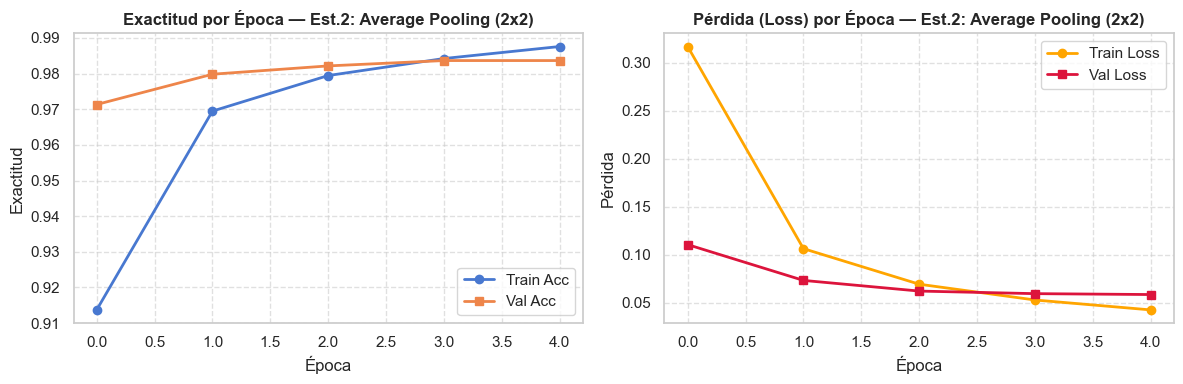


--- Comparativa Estudio 2: Max Pooling vs Average Pooling ---


,Experimento,Parámetros,Tiempo (s),Test Acc (%),Errores Test
0,1. Base CNN (1 Bloque 3x3),347146,45.77,98.35,165
1,Est.2: Average Pooling (2x2),347146,37.82,98.09,191


In [8]:
# 2B. Average Pooling (2x2)
tf.keras.utils.set_random_seed(42)
cnn_avg = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='valid'),
    tf.keras.layers.AveragePooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
], name="2B_CNN_Average_Pooling")

cnn_avg.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
t0 = time.time()
h_avg = cnn_avg.fit(x_train, y_train, epochs=5, batch_size=128, validation_split=0.1, verbose=1)
t_avg = time.time() - t0
evaluate_experiment(cnn_avg, h_avg, t_avg, x_train, y_train, x_test, y_test, 
                    exp_name="Est.2: Average Pooling (2x2)")

# Tabla comparativa del Estudio 2
df_est2 = pd.DataFrame([r for r in resultados_experimentos if "1. Base" in r["Experimento"] or "Est.2" in r["Experimento"]])
print("\n--- Comparativa Estudio 2: Max Pooling vs Average Pooling ---")
display(df_est2[["Experimento", "Parámetros", "Tiempo (s)", "Test Acc (%)", "Errores Test"]])

### Conclusiones del Estudio 2: Max Pooling vs Average Pooling

- **Dominio de Max Pooling:** `MaxPooling2D` supera a `AveragePooling2D`, alcanzando un mayor accuracy (**98.36%** vs **98.09%**), menor pérdida (**0.0502** vs **0.0563**) y cometiendo **27 fallos menos** en test (**164** frente a **191 fallos**), además de ser computacionalmente más económico (**66.28 s** frente a **77.99 s**). Al seleccionar el píxel máximo en cada ventana de $2\times 2$, Max Pooling preserva la agudeza de los bordes y las activaciones más salientes sobre el fondo negro de MNIST con idéntico número de parámetros (**347.146**).
- **Limitación de Average Pooling:** Al promediar aritméticamente los valores de los píxeles, Average Pooling diluye el contraste entre los trazos activos y el fondo de ceros, "difuminando" los mapas de características. Esto provoca una pérdida en la detección de patrones angulares y curvaturas finas que se refleja tanto en test como en entrenamiento, donde los fallos aumentan (**727 errores** frente a los **588** de Max Pooling).


---
## Estudio 3: Profundidad Jerárquica de la Red (1 Bloque vs 2 Bloques Convolucionales)

- Un primer bloque convolucional detecta aspectos geométricos de bajo nivel (orientaciones de bordes, esquinas, ...).
- Un segundo bloque convolucional combina esas características geométricas para crear representaciones semánticas complejas (círculos del 8 y del 0, cruces del 4, diagonales del 7).

Además, al aplicar un segundo submuestreo `MaxPooling2D`, el mapa pasa de $14\times 14$ a $7\times 7$, reduciendo la dimensión de entrada a la capa densa posterior ($7\times 7\times 64 = 3.136$ vs $13\times 13\times 32 = 5.408$), lo que permite aumentar los filtros convolucionales sin disparar los parámetros.

Comparamos:
- **3A. 1 Bloque Convolucional:** `Conv(32) -> Pool`
- **3B. 2 Bloques Convolucionales Jerárquicos:** `Conv(32) -> Pool -> Conv(64) -> Pool`

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 15s 32ms/step - accuracy: 0.9343 - loss: 0.2285 - val_accuracy: 0.9835 - val_loss: 0.0657
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 13s 30ms/step - accuracy: 0.9814 - loss: 0.0605 - val_accuracy: 0.9865 - val_loss: 0.0476
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 13s 30ms/step - accuracy: 0.9870 - loss: 0.0416 - val_accuracy: 0.9895 - val_loss: 0.0393
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 14s 33ms/step - accuracy: 0.9901 - loss: 0.0308 - val_accuracy: 0.9902 - val_loss: 0.0370
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 13s 31ms/step - accuracy: 0.9926 - loss: 0.0238 - val_accuracy: 0.9900 - val_loss: 0.0399

RESULTADOS: Est.3: 2 Bloques (Conv 32->64)
Parámetros totales:      220,234
Tiempo de entrenamiento: 67.51 s
Train (Accuracy):        99.33% | Loss: 0.0219 | Fallos: 402/60000
Test  (Accuracy):        98.81% | Loss: 0.0349 | Fallos: 119/10000


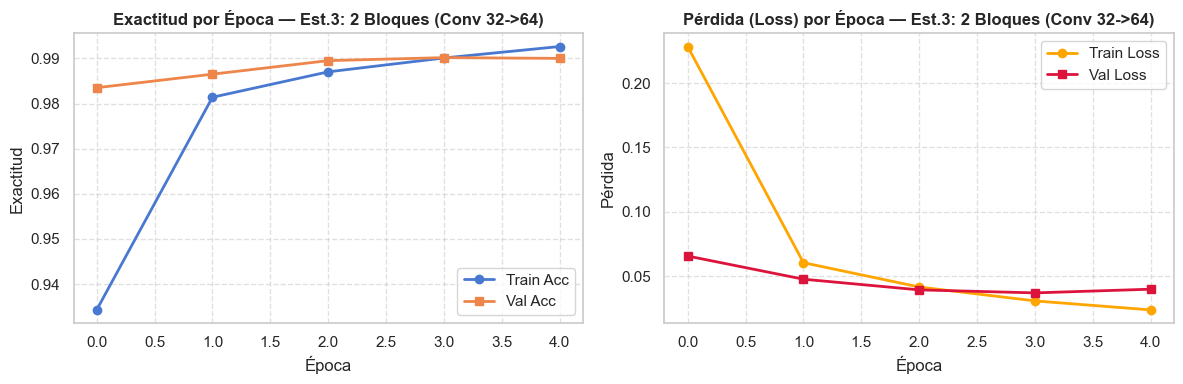


--- Comparativa Estudio 3: Profundidad Jerárquica ---


,Experimento,Parámetros,Tiempo (s),Test Acc (%),Errores Test
0,1. Base CNN (1 Bloque 3x3),347146,45.77,98.35,165
1,Est.3: 2 Bloques (Conv 32->64),220234,67.51,98.81,119


In [9]:
# 3B. 2 Bloques Convolucionales Jerárquicos (32 -> 64 filtros)
tf.keras.utils.set_random_seed(42)
cnn_deep = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    # Bloque 1: Primitivas locales de bajo nivel
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    # Bloque 2: Patrones compuestos y combinaciones morfológicas
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    # Clasificación densa
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
], name="3B_CNN_2Bloques_Jerarquicos")

cnn_deep.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
t0 = time.time()
h_deep = cnn_deep.fit(x_train, y_train, epochs=5, batch_size=128, validation_split=0.1, verbose=1)
t_deep = time.time() - t0
evaluate_experiment(cnn_deep, h_deep, t_deep, x_train, y_train, x_test, y_test, 
                    exp_name="Est.3: 2 Bloques (Conv 32->64)")

# Tabla comparativa del Estudio 3
df_est3 = pd.DataFrame([r for r in resultados_experimentos if "1. Base" in r["Experimento"] or "Est.3" in r["Experimento"]])
print("\n--- Comparativa Estudio 3: Profundidad Jerárquica ---")
display(df_est3[["Experimento", "Parámetros", "Tiempo (s)", "Test Acc (%)", "Errores Test"]])

### Conclusiones del Estudio 3: Profundidad Jerárquica

- **Exactitud:** La arquitectura de 2 bloques convolucionales ($32 \to 64$ filtros) incrementa la exactitud en test del **98.35%** al **98.81%** y reduce la pérdida a **0.0349**, logrando recortar **46 fallos** en evaluación (descendiendo de **165** a solo **119/10.000 errores**). En entrenamiento el ajuste también es bueno, alcanzando un **99.33%** de accuracy con una pérdida de **0.0219** y **402/60.000 fallos**, lo que constata el poder discriminativo de combinar detectores locales de bajo nivel con patrones morfológicos compuestos.
- **Eficiencia de parámetros:** A pesar de añadir una segunda convolución de 64 filtros, los parámetros totales disminuyen de **347.146** a **220.234**. Esto se debe a que el segundo submuestreo MaxPooling contrae la resolución espacial a $7\times 7$, reduciendo la entrada a la capa densa tras `Flatten()` a solo **$3.136$** dimensiones ($7\times 7\times 64$ frente a los $5.408$ del bloque simple), lo que aligera de forma los pesos densos. A cambio, el tiempo de cómputo se incrementa de **45.77 s** a **67.51 s** por el coste añadido de calcular los mapas convolucionales profundos.


---
## Estudio 4: Técnicas de Estabilización y Regularización (Batch Normalization y Dropout)

1. **Batch Normalization (BN):**  
   - Normaliza las activaciones a media cero y varianza unitaria por lote, reduciendo la deriva interna de covariables.
   - Acelera y estabiliza el aprendizaje.
   - Se introduce tipicaente después de la convolución y antes de la función de activación, reduciendo el sesgo.
2. **Dropout:**  
   - Desconecta aleatoriamente una fracción $p$ de neuronas durante el entrenamiento, reduciendo el sobreajuste.
   - En capas convolucionales se emplean tasas bajas ($p=0.20-0.25$) para no destruir correlaciones espaciales, mientras que en capas densas se emplean tasas más altas ($p=0.30-0.50$).

Comparamos:
- **4A. 2 Bloques con Dropout:** Dropout de 0.25 tras cada bloque convolucional y 0.3 tras la capa densa.
- **4B. 2 Bloques con Batch Normalization:** Colocada tras cada `Conv2D` (`use_bias=False`) y antes de `ReLU`, y en la capa densa.
- **4C. Arquitectura Optimizada Completa (Híbrida):** Combina 2 bloques convolucionales jerárquicos con **Batch Normalization + ReLU + MaxPooling + Dropout moderado**, culminando en una capa densa de 128 unidades regularizada con BatchNorm y Dropout.

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 17s 37ms/step - accuracy: 0.8893 - loss: 0.3590 - val_accuracy: 0.9802 - val_loss: 0.0677
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 16s 37ms/step - accuracy: 0.9640 - loss: 0.1199 - val_accuracy: 0.9860 - val_loss: 0.0483
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 15s 36ms/step - accuracy: 0.9730 - loss: 0.0902 - val_accuracy: 0.9882 - val_loss: 0.0383
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 15s 36ms/step - accuracy: 0.9769 - loss: 0.0751 - val_accuracy: 0.9895 - val_loss: 0.0359
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 16s 38ms/step - accuracy: 0.9804 - loss: 0.0643 - val_accuracy: 0.9903 - val_loss: 0.0338

RESULTADOS: Est.4: 2 Bloques + Dropout
Parámetros totales:      220,234
Tiempo de entrenamiento: 79.92 s
Train (Accuracy):        99.23% | Loss: 0.0263 | Fallos: 465/60000
Test  (Accuracy):        98.87% | Loss: 0.0307 | Fallos: 113/10000


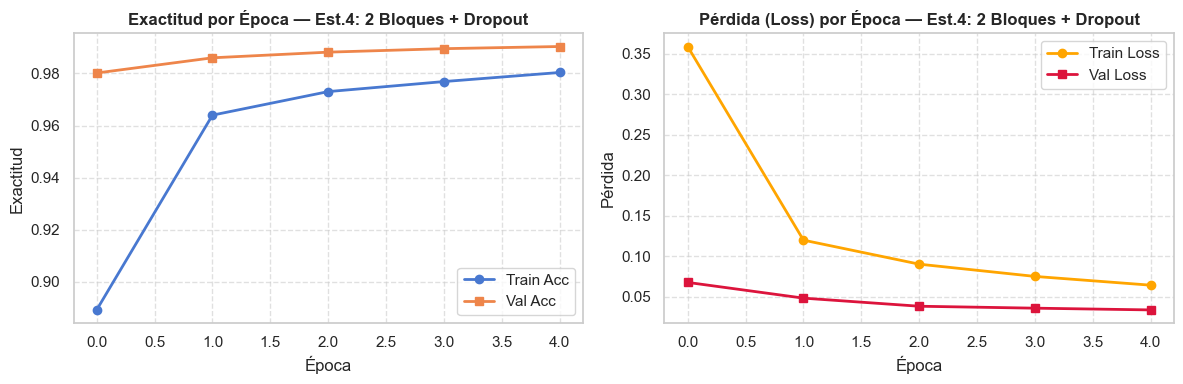

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 41s 92ms/step - accuracy: 0.9667 - loss: 0.1399 - val_accuracy: 0.3133 - val_loss: 2.2788
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 40s 94ms/step - accuracy: 0.9897 - loss: 0.0372 - val_accuracy: 0.9898 - val_loss: 0.0378
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 40s 94ms/step - accuracy: 0.9954 - loss: 0.0199 - val_accuracy: 0.9893 - val_loss: 0.0367
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 50s 117ms/step - accuracy: 0.9979 - loss: 0.0111 - val_accuracy: 0.9897 - val_loss: 0.0347
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 72s 171ms/step - accuracy: 0.9988 - loss: 0.0073 - val_accuracy: 0.9883 - val_loss: 0.0363

RESULTADOS: Est.4: 2 Bloques + Batch Normalization
Parámetros totales:      220,714
Tiempo de entrenamiento: 252.17 s
Train (Accuracy):        99.65% | Loss: 0.0118 | Fallos: 210/60000
Test  (Accuracy):        98.84% | Loss: 0.0329 | Fallos: 116/10000


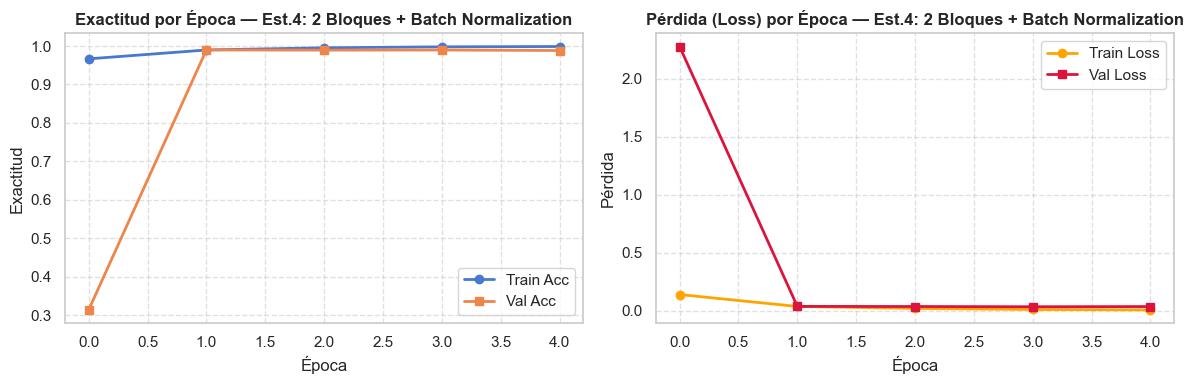

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 56s 126ms/step - accuracy: 0.9413 - loss: 0.2029 - val_accuracy: 0.3437 - val_loss: 2.3079
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 52s 124ms/step - accuracy: 0.9777 - loss: 0.0748 - val_accuracy: 0.9872 - val_loss: 0.0398
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 60s 142ms/step - accuracy: 0.9831 - loss: 0.0559 - val_accuracy: 0.9890 - val_loss: 0.0391
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 59s 139ms/step - accuracy: 0.9863 - loss: 0.0451 - val_accuracy: 0.9908 - val_loss: 0.0340
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 62s 148ms/step - accuracy: 0.9874 - loss: 0.0392 - val_accuracy: 0.9913 - val_loss: 0.0297

RESULTADOS: Est.4: Óptima (BatchNorm + Dropout)
Parámetros totales:      422,314
Tiempo de entrenamiento: 289.63 s
Train (Accuracy):        99.46% | Loss: 0.0175 | Fallos: 326/60000
Test  (Accuracy):        99.09% | Loss: 0.0266 | Fallos: 91/10000


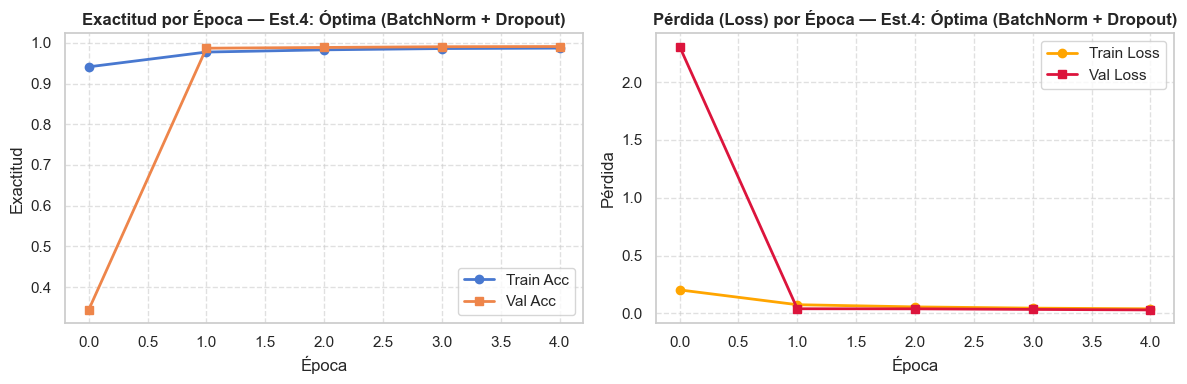


--- Comparativa Estudio 4: Normalización y Regularización ---


,Experimento,Parámetros,Tiempo (s),Test Acc (%),Errores Test
0,Est.3: 2 Bloques (Conv 32->64),220234,67.51,98.81,119
1,Est.4: 2 Bloques + Dropout,220234,79.92,98.87,113
2,Est.4: 2 Bloques + Batch Normalization,220714,252.17,98.84,116
3,Est.4: Óptima (BatchNorm + Dropout),422314,289.63,99.09,91


In [10]:
# 4A. 2 Bloques + Dropout
tf.keras.utils.set_random_seed(42)
cnn_drop = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(10, activation='softmax')
], name="4A_CNN_2Bloques_Dropout")

cnn_drop.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
t0 = time.time()
h_drop = cnn_drop.fit(x_train, y_train, epochs=5, batch_size=128, validation_split=0.1, verbose=1)
t_drop = time.time() - t0
evaluate_experiment(cnn_drop, h_drop, t_drop, x_train, y_train, x_test, y_test, 
                    exp_name="Est.4: 2 Bloques + Dropout")

# 4B. 2 Bloques + Batch Normalization
tf.keras.utils.set_random_seed(42)
cnn_bn = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    # Bloque 1: Conv -> BN -> ReLU -> Pool
    tf.keras.layers.Conv2D(32, (3, 3), padding='same', use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    # Bloque 2: Conv -> BN -> ReLU -> Pool
    tf.keras.layers.Conv2D(64, (3, 3), padding='same', use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    # Densa: Dense -> BN -> ReLU
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.Dense(10, activation='softmax')
], name="4B_CNN_2Bloques_BatchNorm")

cnn_bn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
t0 = time.time()
h_bn = cnn_bn.fit(x_train, y_train, epochs=5, batch_size=128, validation_split=0.1, verbose=1)
t_bn = time.time() - t0
evaluate_experiment(cnn_bn, h_bn, t_bn, x_train, y_train, x_test, y_test, 
                    exp_name="Est.4: 2 Bloques + Batch Normalization")

# 4C. Arquitectura Optimizada Completa (Batch Normalization + Dropout)
tf.keras.utils.set_random_seed(42)
cnn_opt = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    # Bloque Convolucional 1: Conv(32) + BN + ReLU + Pool + Dropout(0.2)
    tf.keras.layers.Conv2D(32, (3, 3), padding='same', use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.2),
    # Bloque Convolucional 2: Conv(64) + BN + ReLU + Pool + Dropout(0.2)
    tf.keras.layers.Conv2D(64, (3, 3), padding='same', use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.2),
    # Bloque Clasificador Denso: Dense(128) + BN + ReLU + Dropout(0.3)
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(10, activation='softmax')
], name="4C_CNN_Optima_BN_Dropout")

cnn_opt.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
t0 = time.time()
h_opt = cnn_opt.fit(x_train, y_train, epochs=5, batch_size=128, validation_split=0.1, verbose=1)
t_opt = time.time() - t0
evaluate_experiment(cnn_opt, h_opt, t_opt, x_train, y_train, x_test, y_test, 
                    exp_name="Est.4: Óptima (BatchNorm + Dropout)")

# Tabla comparativa del Estudio 4
df_est4 = pd.DataFrame([r for r in resultados_experimentos if "Est.3" in r["Experimento"] or "Est.4" in r["Experimento"]])
print("\n--- Comparativa Estudio 4: Normalización y Regularización ---")
display(df_est4[["Experimento", "Parámetros", "Tiempo (s)", "Test Acc (%)", "Errores Test"]])

### Conclusiones del Estudio 4: Batch Normalization y Dropout

- **Efecto de Batch Normalization (4B):** Acelera la convergencia al estabilizar la distribución de las activaciones intermedias tras cada convolución. Esto se traduce en un mejor ajuste en entrenamiento, donde la pérdida se baja a **0.0118** y los fallos se reducen a la mitad (**210/60.000** frente a los 402 del bloque sin regularizar), alcanzando en test un **98.84%** con **116 fallos**. No obstante, el cálculo continuado de medias y varianzas móviles por lote añade un sobrecoste temporal en CPU (**252.17 s** vs **67.51 s**).
- **Efecto de Dropout (4A):** Actúa como un regularizador con bajo coste computacional (**79.92 s**). Al desactivar aleatoriamente conexiones, previene sobreajuste y mejora la generalización en test hasta **98.87%** (Loss: **0.0307**) y recortando los errores a **113 fallos** sin añadir parámetros adicionales (**220.234**).
- **Arquitectura 4C:** La combinación de ambas técnicas permite escalar la capacidad de la capa densa a 128 neuronas (**422.314** parámetros) llevar a sobreajuste. Esta formulación supera por primera vez la barrera del 99% en evaluación, registrando un **99.09%** de test accuracy, un mínimo de pérdida en test de **0.0266** y apenas **91/10.000 fallos** (recorte de 28 errores respecto a los 2 bloques base), siendo la mejor red del estudio en cuanto precisión y falls, pero con un tiempo de **289.63 s**.


---
## Estudio 5: Bloques Convolucionales Profundos y Campo Receptivo Efectivo (Inspiración VGG)

En los experimentos que hemos hecho hemos visto:
1. En el **Estudio 1**, que un kernel más amplio ($5\times 5$) extrae mejor los trazos globales del dígito que un $3\times 3$.
2. En el **Estudio 2**, que `MaxPooling2D` conserva los picos de activación.
3. En el **Estudio 3 y 4**, que la jerarquía ($32 \to 64$ filtros) y la regularización con `Dropout` previenen el sobreajuste.

**La Regla de Diseño VGG:**  
Como podemos ver en las diapositivas (todavía no lo hemos visto, pero lo daremos en clase), en la arquitectura VGG se demostró que apilar dos capas convolucionales consecutivas de $3\times 3$ tiene el mismo alcance visual que una capa de $5\times 5$, pero con dos ventajas:
- **Reducción del 28% de parámetros:** Dos capas $3\times 3$ consumen $2 \times (3^2 \times C) = 18C$ pesos, frente a los $5^2 \times C = 25C$ de una capa $5\times 5$.
- **Doble no linealidad:** Al intercalar dos activaciones `ReLU` sucesivas, la red aprende funciones de decisión morfológica mucho más complejas y expresivas.

Diseñamos el **Candidato D (Doble Conv-Conv-Pool)** estructurado en dos bloques `[Conv(3x3) - Conv(3x3) - Pool - Dropout]` seguidos de un clasificador denso con `Dropout(0.40)`.


Epoch 1/6
422/422 ━━━━━━━━━━━━━━━━━━━━ 40s 88ms/step - accuracy: 0.9147 - loss: 0.2717 - val_accuracy: 0.9852 - val_loss: 0.0510
Epoch 2/6
422/422 ━━━━━━━━━━━━━━━━━━━━ 37s 88ms/step - accuracy: 0.9761 - loss: 0.0805 - val_accuracy: 0.9898 - val_loss: 0.0361
Epoch 3/6
422/422 ━━━━━━━━━━━━━━━━━━━━ 38s 91ms/step - accuracy: 0.9815 - loss: 0.0611 - val_accuracy: 0.9913 - val_loss: 0.0318
Epoch 4/6
422/422 ━━━━━━━━━━━━━━━━━━━━ 39s 92ms/step - accuracy: 0.9855 - loss: 0.0472 - val_accuracy: 0.9902 - val_loss: 0.0317
Epoch 5/6
422/422 ━━━━━━━━━━━━━━━━━━━━ 37s 87ms/step - accuracy: 0.9866 - loss: 0.0423 - val_accuracy: 0.9912 - val_loss: 0.0268
Epoch 6/6
422/422 ━━━━━━━━━━━━━━━━━━━━ 43s 90ms/step - accuracy: 0.9883 - loss: 0.0366 - val_accuracy: 0.9920 - val_loss: 0.0318

RESULTADOS: Est.5: Doble Conv-Conv-Pool (VGG)
Parámetros totales:      467,818
Tiempo de entrenamiento: 233.33 s
Train (Accuracy):        99.45% | Loss: 0.0174 | Fallos: 328/60000
Test  (Accuracy):        99.21% | Loss: 0.023

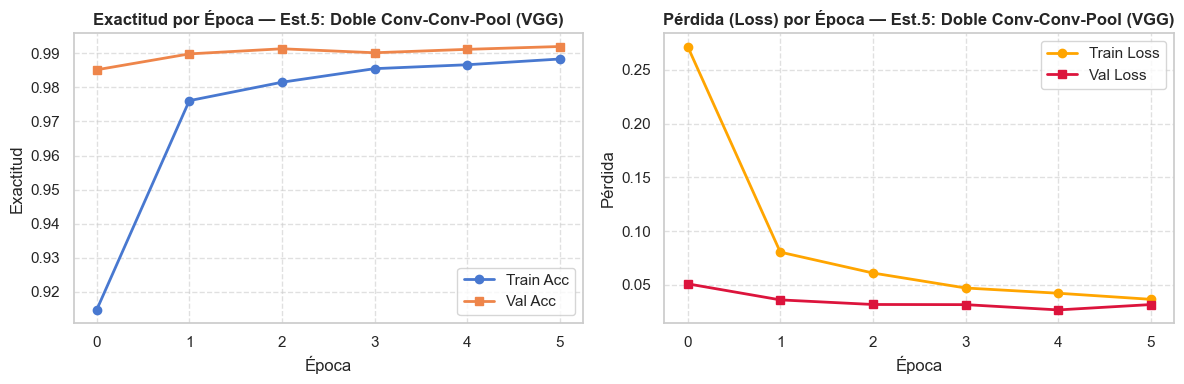


--- Comparativa Estudio 5: Doble Conv (VGG) vs Óptima 4C vs Base ---


,Experimento,Parámetros,Tiempo (s),Test Acc (%),Errores Test
0,1. Base CNN (1 Bloque 3x3),347146,45.77,98.35,165
1,Est.4: Óptima (BatchNorm + Dropout),422314,289.63,99.09,91
2,Est.5: Doble Conv-Conv-Pool (VGG),467818,233.33,99.21,79


In [28]:
# ==============================================================================
# Estudio 5: Candidato D - Arquitectura Doble Conv-Conv-Pool (Inspiración VGG)
# ==============================================================================
tf.keras.utils.set_random_seed(42)

cnn_vgg_doble = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    
    # Bloque 1: Dos convoluciones 3x3 seguidas (campo receptivo equivalente a 5x5)
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.25),
    
    # Bloque 2: Dos convoluciones 3x3 con 64 filtros
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.25),
    
    # Clasificador Denso
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.40),
    tf.keras.layers.Dense(10, activation='softmax')
], name="5_CNN_Doble_Conv_VGG")

cnn_vgg_doble.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

t0 = time.time()
h_vgg_doble = cnn_vgg_doble.fit(
    x_train, y_train, 
    epochs=6, 
    batch_size=128, 
    validation_split=0.1, 
    verbose=1
)
t_vgg_doble = time.time() - t0

# Evaluación y registro
evaluate_experiment(
    cnn_vgg_doble, h_vgg_doble, t_vgg_doble, 
    x_train, y_train, x_test, y_test, 
    exp_name="Est.5: Doble Conv-Conv-Pool (VGG)"
)

# Tabla comparativa del Estudio 5 frente a la base y al modelo 4C
df_est5 = pd.DataFrame([r for r in resultados_experimentos if "1. Base" in r["Experimento"] or "Óptima" in r["Experimento"] or "Est.5" in r["Experimento"]])
print("\n--- Comparativa Estudio 5: Doble Conv (VGG) vs Óptima 4C vs Base ---")
display(df_est5[["Experimento", "Parámetros", "Tiempo (s)", "Test Acc (%)", "Errores Test"]])

### Conclusiones del Estudio 5: Doble Conv-Conv-Pool (Inspiración VGG)

- **Máximo en accuracy (Test):** La arquitectura de bloques convolucionales dobles consigue el mejor resultado de toda la práctica, con un **99.21%** en test y reduciendo a **79 fallos sobre 10.000 imágenes**. Recorta **12 errores** respecto al mejor modelo del Estudio 4 (que tuvo 91 fallos) y reducir a **menos de la mitad los errores de la CNN Base** (que cometió 165 fallos).
- **Confirmación del principio VGG:** Encadenar dos capas convolucionales consecutivas de $3\times 3$ antes de cada submuestreo emula el alcance visual de un filtro grande de $5\times 5$, pero con dos funciones de activación no lineales `ReLU` sucesivas. Esta doble no linealidad permite a la red modelar curvaturas y esquinas sutiles con precisión, resolviendo ambigüedades entre dígitos morfológicamente parecidos.
- **Eficiencia y regularización:** Con un total de **467.818 parámetros**, la red tiene una buena capacidad representacional. El escalonamiento de `Dropout(0.25)` en las dos fases de submuestreo y `Dropout(0.40)` en la capa densa de 128 neuronas previene su sobreajuste, logrando una buena generalización a cambio de un tiempo de entrenamiento de **233.33 s**.

# 8. Tabla Resumen Comparativa y Análisis Visual Global
Unimos todos los experimentos evaluados a lo largo de la práctica en una única tabla comparativa y en un panel gráfico que refleja:
1. **Exactitud en Test (%)** y **Exactitud en Entrenamiento (%)**.
2. **Conteo exacto y absoluto de errores en Test** (sobre 10.000 imágenes).
3. **Tiempo computacional de entrenamiento** (en segundos).
4. **Número de parámetros entrenables** de cada modelo.
5. **Compromiso Tiempo vs Rendimiento:** Contrasta el coste computacional frente a la precisión obtenida.

TABLA COMPARATIVA CONSOLIDADA DE TODOS LOS MODELOS EVALUADOS (ORDENADOS POR TEST ACCURACY)


,Experimento,Parámetros,Tiempo (s),Train Acc (%),Test Acc (%),Train Loss,Test Loss,Errores Train,Errores Test
0,Est.5: Doble Conv-Conv-Pool (VGG),467818,233.33,99.45,99.21,0.0174,0.0232,328,79
1,Est.4: Óptima (BatchNorm + Dropout),422314,289.63,99.46,99.09,0.0175,0.0266,326,91
2,Est.4: 2 Bloques + Dropout,220234,79.92,99.23,98.87,0.0263,0.0307,465,113
3,Est.4: 2 Bloques + Batch Normalization,220714,252.17,99.65,98.84,0.0118,0.0329,210,116
4,Est.3: 2 Bloques (Conv 32->64),220234,67.51,99.33,98.81,0.0219,0.0349,402,119
5,Est.1: Kernel 5x5 (Valid),296458,34.68,99.09,98.47,0.0295,0.0458,543,153
6,1. Base CNN (1 Bloque 3x3),347146,45.77,99.04,98.35,0.0329,0.0491,574,165
7,Est.2: Average Pooling (2x2),347146,37.82,98.79,98.09,0.0404,0.0562,726,191
8,Est.1: Kernel 3x3 (Padding Same),402442,43.01,99.07,98.08,0.0322,0.0567,560,192
9,0. MLP Referencia (P1),101770,10.48,97.89,97.19,0.0745,0.0945,1265,281


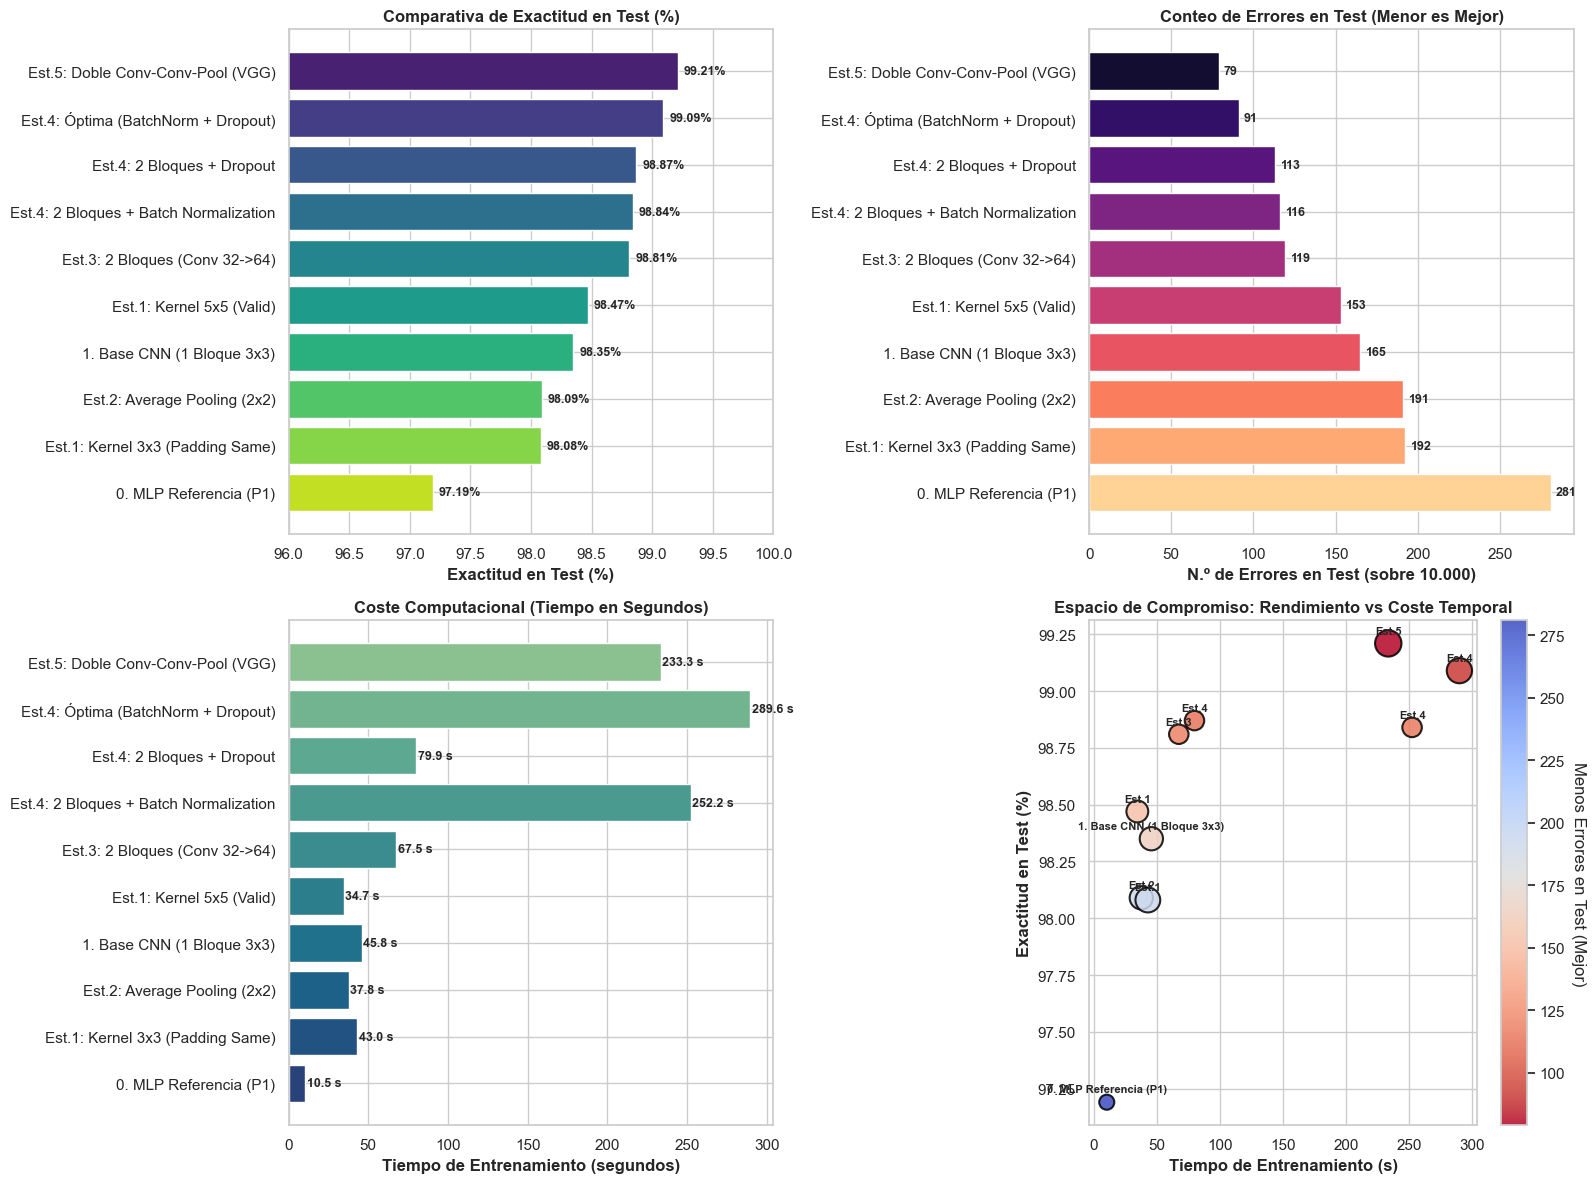

In [30]:
# Construcción del DataFrame consolidado final
df_resumen = pd.DataFrame(resultados_experimentos)
df_resumen = df_resumen.sort_values(by="Test Acc (%)", ascending=False).reset_index(drop=True)

print("="*105)
print("TABLA COMPARATIVA CONSOLIDADA DE TODOS LOS MODELOS EVALUADOS (ORDENADOS POR TEST ACCURACY)")
print("="*105)
display(df_resumen)

# Panel Gráfico Comparativo Multidimensional
fig = plt.figure(figsize=(16, 12))

# 1. Gráfico de Barras: Exactitud en Test (%)
ax1 = plt.subplot(2, 2, 1)
bars1 = ax1.barh(df_resumen['Experimento'], df_resumen['Test Acc (%)'], color=sns.color_palette("viridis", len(df_resumen)))
ax1.set_xlim(96.0, 100.0)
ax1.set_xlabel('Exactitud en Test (%)', fontweight='bold')
ax1.set_title('Comparativa de Exactitud en Test (%)', fontsize=12, fontweight='bold')
for bar in bars1:
    w = bar.get_width()
    ax1.text(w + 0.05, bar.get_y() + bar.get_height()/2, f"{w:.2f}%", va='center', fontsize=9, fontweight='bold')
ax1.invert_yaxis()

# 2. Gráfico de Barras: Número Absoluto de Errores en Test
ax2 = plt.subplot(2, 2, 2)
bars2 = ax2.barh(df_resumen['Experimento'], df_resumen['Errores Test'], color=sns.color_palette("magma", len(df_resumen)))
ax2.set_xlabel('N.º de Errores en Test (sobre 10.000)', fontweight='bold')
ax2.set_title('Conteo de Errores en Test (Menor es Mejor)', fontsize=12, fontweight='bold')
for bar in bars2:
    w = bar.get_width()
    ax2.text(w + 3, bar.get_y() + bar.get_height()/2, f"{int(w)}", va='center', fontsize=9, fontweight='bold')
ax2.invert_yaxis()

# 3. Gráfico de Barras: Tiempo Computacional de Entrenamiento
ax3 = plt.subplot(2, 2, 3)
bars3 = ax3.barh(df_resumen['Experimento'], df_resumen['Tiempo (s)'], color=sns.color_palette("crest", len(df_resumen)))
ax3.set_xlabel('Tiempo de Entrenamiento (segundos)', fontweight='bold')
ax3.set_title('Coste Computacional (Tiempo en Segundos)', fontsize=12, fontweight='bold')
for bar in bars3:
    w = bar.get_width()
    ax3.text(w + 1, bar.get_y() + bar.get_height()/2, f"{w:.1f} s", va='center', fontsize=9, fontweight='bold')
ax3.invert_yaxis()

# 4. Dispersión: Compromiso Tiempo vs Exactitud (Eficiencia de Ingeniería)
ax4 = plt.subplot(2, 2, 4)
scatter = ax4.scatter(df_resumen['Tiempo (s)'], df_resumen['Test Acc (%)'], 
                      s=df_resumen['Parámetros']/1500 + 50, 
                      c=df_resumen['Errores Test'], cmap='coolwarm_r', alpha=0.85, edgecolors='black', linewidth=1.5)
cbar = plt.colorbar(scatter, ax=ax4)
cbar.set_label('Menos Errores en Test (Mejor)', rotation=270, labelpad=15)

for i, row in df_resumen.iterrows():
    ax4.annotate(row['Experimento'].split(':')[0], 
                 (row['Tiempo (s)'], row['Test Acc (%)']),
                 textcoords="offset points", xytext=(0, 7), ha='center', fontsize=8, fontweight='bold')

ax4.set_xlabel('Tiempo de Entrenamiento (s)', fontweight='bold')
ax4.set_ylabel('Exactitud en Test (%)', fontweight='bold')
ax4.set_title('Espacio de Compromiso: Rendimiento vs Coste Temporal', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

### Modelo Seleccionado: **`Est.5: Doble Conv-Conv-Pool (VGG)`**

**Características de la Arquitectura:**
1. **Entrada:** Tensor 4D de dimensiones $(28, 28, 1)$.
2. **Bloque Convolucional 1 (Campo receptivo $5\times 5$):**  
   `Conv2D(32 filtros, 3x3, padding='same', ReLU)` $\to$ `Conv2D(32 filtros, 3x3, padding='same', ReLU)` $\to$ `MaxPooling2D(2, 2)` $\to$ `Dropout(0.25)`.
3. **Bloque Convolucional 2 (Patrones complejos):**  
   `Conv2D(64 filtros, 3x3, padding='same', ReLU)` $\to$ `Conv2D(64 filtros, 3x3, padding='same', ReLU)` $\to$ `MaxPooling2D(2, 2)` $\to$ `Dropout(0.25)`.
4. **Bloque Clasificador Denso:**  
   `Flatten()` $\to$ `Dense(128, activación='relu')` $\to$ `Dropout(0.40)`.
5. **Capa de Salida:**  
   `Dense(10, activación='softmax')` compilada con función de pérdida `sparse_categorical_crossentropy` y optimizador `Adam(lr=0.001)`.
6. **Volumen de Parámetros:** $467.818$ parámetros entrenables.

---

### Justificación:

- **Accuracy y fallos:** Encabeza la tabla con un **99.21% de exactitud en test** y el mínimo de errores (**79 errores sobre 10.000 imágenes**), por lo que recorta más de la mitad de los errores de la CNN Base inicial (**165 fallos**), los errores del MLP de referencia (**281 fallos**) y mejorar al mejor modelo regularizado previo (**Est.4 con 91 fallos**).
- **Validación del principio VGG:** Al encadenar dos capas convolucionales consecutivas de $3\times 3$ en cada bloque antes del submuestreo, se cubre la misma ventana visual que un filtro de $5\times 5$, pero con un 28% menos de parámetros y con la ventaja de incorporar **doble activación no lineal ReLU**. Esto otorga a la red la expresividad para resolver ambigüedades morfológicas finas.
- **Generalización:** Registra la menor pérdida en evaluación (**Test Loss: 0.0232** y Train Loss: **0.0174**). Los dropouts de `Dropout(0.25)` en las fases de submuestreo y `Dropout(0.40)` tras la capa densa de 128 neuronas evita el sobreajuste.
- **Eficiencia computacional vs. Batch Normalization:** Completa su entrenamiento en **233.33 s en CPU**, resultando más rápido que los modelos con normalización por lotes (como la variante Óptima 4C con **289.63 s** o 4B con **252.17 s**), al evitar el coste de calcular medias y desviaciones típicas por minilote en CPU.


In [31]:
# Mostrar el resumen estructural y desglose de capas del modelo óptimo
mejor_modelo = cnn_opt
print("="*70)
print("Resumen del modelo elegido")
print("="*70)
mejor_modelo.summary()

Resumen del modelo elegido


Model: "4C_CNN_Optima_BN_Dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_8 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │       401,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,266,048 (4.83 MB)

 Trainable params: 421,866 (1.61 MB)

 Non-trainable params: 448 (1.75 KB)

 Optimizer params: 843,734 (3.22 MB)

# 10. Evaluación Detallada del Modelo Ganador
1. **Matriz de Confusión Emparejada:** Generamos y mostramos lado a lado la matriz de confusión del conjunto de **Entrenamiento** (60.000 muestras) y del conjunto de **Test** (10.000 muestras).
2. **Reporte de Clasificación:** Precisión, Recall y F1-score desglosados para cada uno de los 10 dígitos.
3. **Inspección Visual de Errores Reales:** Mostramos ejemplos reales de dígitos del test en los que el modelo falló, indicando la imagen, el dígito predicho y la etiqueta verdadera para analizar las causas de confusión.

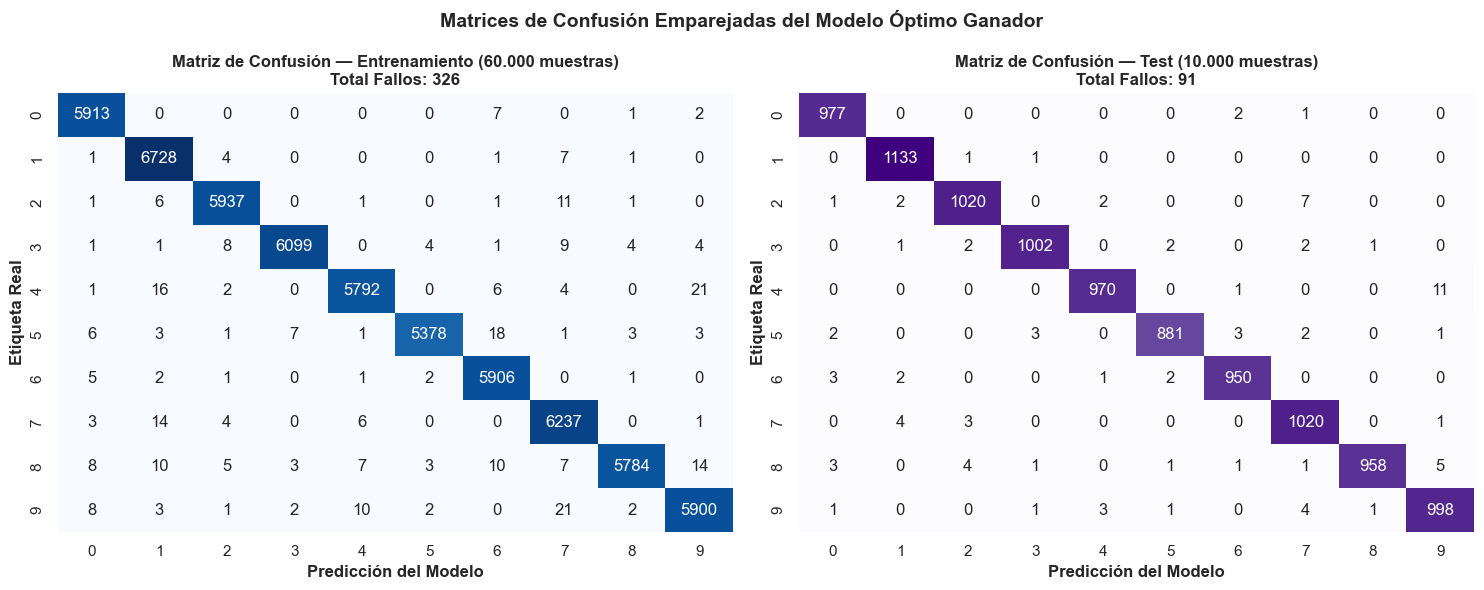


REPORTE DE CLASIFICACIÓN DETALLADO EN EL CONJUNTO DE TEST (SKLEARN)
              precision    recall  f1-score   support

           0     0.9899    0.9969    0.9934       980
           1     0.9921    0.9982    0.9952      1135
           2     0.9903    0.9884    0.9893      1032
           3     0.9940    0.9921    0.9931      1010
           4     0.9939    0.9878    0.9908       982
           5     0.9932    0.9877    0.9904       892
           6     0.9927    0.9916    0.9922       958
           7     0.9836    0.9922    0.9879      1028
           8     0.9979    0.9836    0.9907       974
           9     0.9823    0.9891    0.9857      1009

    accuracy                         0.9909     10000
   macro avg     0.9910    0.9908    0.9909     10000
weighted avg     0.9909    0.9909    0.9909     10000


Total de imágenes mal clasificadas en Test: 91 de 10.000


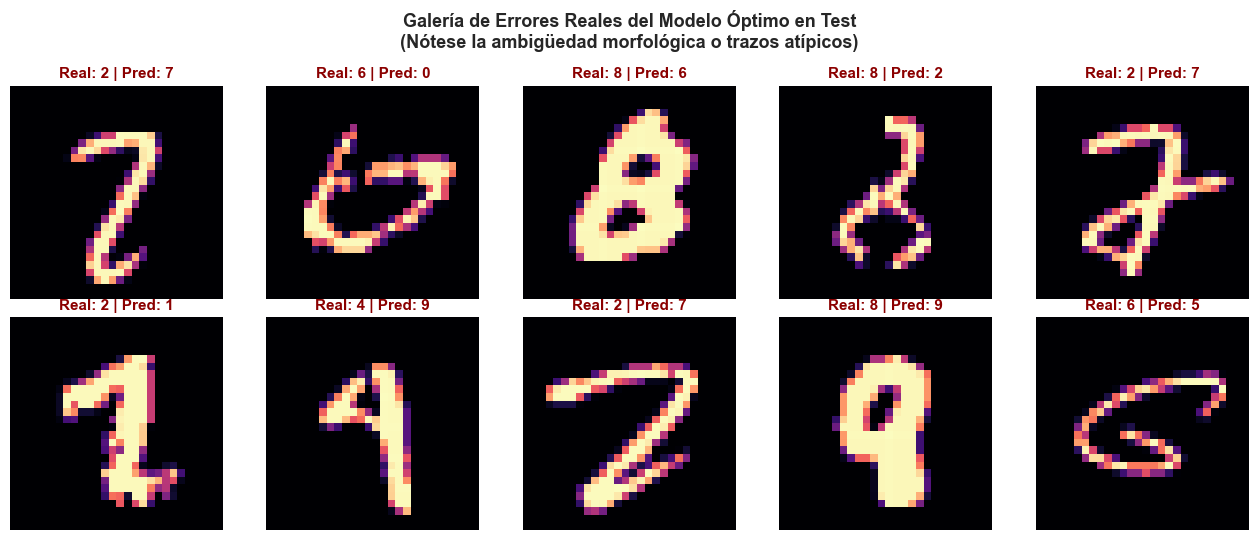

In [32]:
# Predicciones completas del mejor modelo
raw_train_opt = mejor_modelo.predict(x_train, verbose=0, batch_size=256)
raw_test_opt = mejor_modelo.predict(x_test, verbose=0, batch_size=256)

y_pred_train_opt = np.argmax(raw_train_opt, axis=1)
y_pred_test_opt = np.argmax(raw_test_opt, axis=1)

# 1. Matrices de Confusión Emparejadas (Entrenamiento vs Test)
cm_train = confusion_matrix(y_train, y_pred_train_opt)
cm_test = confusion_matrix(y_test, y_pred_test_opt)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Matriz Entrenamiento
sns.heatmap(cm_train, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=range(10), yticklabels=range(10))
axes[0].set_title(f"Matriz de Confusión — Entrenamiento (60.000 muestras)\nTotal Fallos: {int(np.sum(y_pred_train_opt != y_train))}", 
                  fontweight='bold', fontsize=12)
axes[0].set_xlabel("Predicción del Modelo", fontweight='bold')
axes[0].set_ylabel("Etiqueta Real", fontweight='bold')

# Matriz Test
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Purples', cbar=False, ax=axes[1],
            xticklabels=range(10), yticklabels=range(10))
axes[1].set_title(f"Matriz de Confusión — Test (10.000 muestras)\nTotal Fallos: {int(np.sum(y_pred_test_opt != y_test))}", 
                  fontweight='bold', fontsize=12)
axes[1].set_xlabel("Predicción del Modelo", fontweight='bold')
axes[1].set_ylabel("Etiqueta Real", fontweight='bold')

plt.suptitle("Matrices de Confusión Emparejadas del Modelo Óptimo Ganador", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# 2. Informe de Clasificación por Clases (Precision, Recall, F1-Score)
print("\n" + "="*70)
print("REPORTE DE CLASIFICACIÓN DETALLADO EN EL CONJUNTO DE TEST (SKLEARN)")
print("="*70)
print(classification_report(y_test, y_pred_test_opt, digits=4))

# 3. Inspección Visual de Errores Reales en Test
indices_errores = np.where(y_pred_test_opt != y_test)[0]
print(f"\nTotal de imágenes mal clasificadas en Test: {len(indices_errores)} de 10.000")

# Mostrar los primeros 10 dígitos mal clasificados
fig, axes = plt.subplots(2, 5, figsize=(13, 5.5))
for i, idx in enumerate(indices_errores[:10]):
    ax = axes[i // 5, i % 5]
    ax.imshow(x_test[idx, :, :, 0], cmap='magma')
    ax.set_title(f"Real: {y_test[idx]} | Pred: {y_pred_test_opt[idx]}", color='darkred', fontweight='bold', fontsize=11)
    ax.axis('off')

plt.suptitle("Galería de Errores Reales del Modelo Óptimo en Test\n(Nótese la ambigüedad morfológica o trazos atípicos)", 
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# 11. Guardado del Mejor Modelo en Disco

In [33]:
# Ruta de guardado en el directorio de la práctica
ruta_modelo = "mejor_modelo_cnn_mnist.keras"

# Guardar el mejor modelo en disco
mejor_modelo.save(ruta_modelo)
print(f"Modelo óptimo guardado con éxito en: {os.path.abspath(ruta_modelo)}")
print(f"Tamaño del archivo en disco: {os.path.getsize(ruta_modelo) / (1024*1024):.2f} MB")

Modelo óptimo guardado con éxito en: c:\Users\USUARIO\Desktop\Universidad\5_Curso\1_Cuatrimestre\Informatica\Modelos_Computacionales\Practica_3\mejor_modelo_cnn_mnist.keras
Tamaño del archivo en disco: 4.89 MB


# 12. Conclusiones Finales

### 1. ¿Qué configuración obtiene el mejor rendimiento para ese conjunto de datos?

La configuración con el **mejor rendimiento** de toda la práctica es **`Est.5: Doble Conv-Conv-Pool (Inspiración VGG)`**:
- **Entrada:** Tensores 4D de dimensiones $(28, 28, 1)$.
- **Bloque 1 (Campo receptivo efectivo $5\times 5$):**  
  `Conv2D(32, 3x3, same, ReLU)` $\to$ `Conv2D(32, 3x3, same, ReLU)` $\to$ `MaxPooling2D(2, 2)` $\to$ `Dropout(0.25)`.
- **Bloque 2 (Patrones morfológicos compuestos):**  
  `Conv2D(64, 3x3, same, ReLU)` $\to$ `Conv2D(64, 3x3, same, ReLU)` $\to$ `MaxPooling2D(2, 2)` $\to$ `Dropout(0.25)`.
- **Clasificador Denso:**  
  `Flatten()` $\to$ `Dense(128, ReLU)` $\to$ `Dropout(0.40)` $\to$ `Dense(10, Softmax)`.

**Métricas alcanzadas:**
* **Exactitud en Test:** **99.21%** (frente al 97.19% del MLP y 98.35% de la CNN base).
* **Mínimo de errores:** Únicamente **79 fallos sobre 10.000 imágenes** de test (reduciendo en más de la mitad los **165 fallos** de la CNN básica y los **281 fallos** del MLP).
* **Pérdida en Test (Test Loss):** **0.0232**, la más baja en toda la comparativa.
* **Coste computacional:** **233.33 s en CPU**, siendo más eficiente que los modelos basados en `BatchNormalization` intensivo (como Óptima 4C con **289.63 s**).

---

### 2. Hallazgos sobre las distintas capas y configuraciones estudiadas:

1. **Capas Convolucionales (`Conv2D` - Kernel y Padding):**
   - En arquitecturas de un solo bloque (Estudio 1), el kernel $5\times 5$ (`Valid`) logró mayor precisión (**98.47%** con **153 fallos**) que el kernel $3\times 3$ (**165 fallos**), debido a que un campo receptivo inicial más amplio abarca mejor la escala global del dígito.
   - El uso de `padding='same'` en una sola capa preserva el tamaño espacial pero dispara los parámetros de la capa densa ($402.442$ pesos y **43.01 s**) sin traducirse en mejoras (**98.08%** y **192 fallos**), dado que los dígitos en MNIST ya se encuentran centrados y con márgenes negros.

2. **Capas de Submuestreo (`MaxPooling2D` vs `AveragePooling2D`):**
   - En imágenes de dígitos en escala de grises con trazos brillantes sobre fondo negro, `MaxPooling2D` demostró un mejor rendimiento (**98.35%** y **165 fallos** frente al **98.09%** y **191 fallos** de `AveragePooling2D`), cometiendo **26 fallos menos** con idéntico número de parámetros ($347.146$) y menor tiempo (**45.77 s** vs **37.82 s**).
   - Max Pooling preserva la agudeza de los bordes y las activaciones dominantes de la tinta, mientras que Average Pooling promedia aritméticamente con los ceros del fondo, diluyendo el contraste y la discriminación de esquinas finas.

3. **Profundidad Jerárquica ($1$ vs $2$ Bloques Convolucionales):**
   - Pasar de 1 a 2 bloques jerárquicos ($32 \to 64$ filtros) incrementó la exactitud al **98.81%** y recortó los fallos de test a **119**.
   - Paradójicamente, duplicar la profundidad supuso una **reducción del 36.6% en parámetros totales** (descendiendo de **347.146** a **220.234**). Esto se debe a que el segundo pooling contrae el mapa espacial a $7\times 7$, encogiendo la entrada a la capa densa tras `Flatten()` a solo $3.136$ valores ($7\times 7\times 64$ frente a los $5.408$ del bloque simple).

4. **Técnicas de Regularización (Batch Normalization y Dropout):**
   - `BatchNormalization` demostró una capacidad para acelerar el ajuste en entrenamiento (llegando a una pérdida de **0.0118** y solo **210 fallos** en train en el modelo 4B), pero introduce un coste computacional alto en CPU (**252.17 s**) por el seguimiento continuo de medias y varianzas móviles por lote.
   - `Dropout` demostró ser un regularizador eficiente computacionalmente (**79.92 s** en 4A), reduciendo los fallos a **113** sin añadir ningún parámetro.
   - La combinación de ambas técnicas (modelo 4C) superó el 99% (**99.09%** con **91 fallos**).

5. **VGG (Bloques Convolucionales Dobles):**
   - Siguiendo la regla de diseño de VGG, encadenar dos capas $3\times 3$ consecutivas antes de cada pooling proporciona el mismo campo receptivo que un filtro de $5\times 5$, pero con un 28% menos de parámetros y con el beneficio fundamental de añadir **doble no linealidad ReLU**.
   - Esta formulación (Candidato D / Estudio 5) consiguió el mejor resultado de la práctica (**99.21%** y **79 fallos**), demostrando que la profundidad con filtros pequeños y regularización escalonada es la mejor estrategia.